# Qui exploite les mines guinéennes, et que touche l'État ? (2019-2024)

**Question :** quelles entreprises produisent et exportent la bauxite et l'or de la Guinée, la production est-elle concentrée, et combien chaque entreprise verse-t-elle à l'État ?

**Sources** (données par entreprise, recopiées depuis les PDF officiels ; source et page indiquées pour chaque ligne) :
- Ministère des Mines et de la Géologie (MMG), Annuaire statistique des mines et carrières 2023 : tableaux 11, 13, 14 et 25 (2019-2023).
- MMG, Bulletin annuel 2024 : tableaux I-1, I-2, IV-1, VI-1 et VI-2 (2024).
- INS, Note d'analyse du commerce extérieur 2024 : valeur des exportations (étape 1).

Requêtes SQL : `sql/02_*.sql`. Fichiers : `data/bauxite_par_entreprise.csv`, `data/or_par_entreprise.csv`, `data/taxes_bauxite_par_entreprise.csv`.

In [2]:
import sys
sys.path.append("..")

from src.requetes import requete
from src.graphiques import graphique_parts_entreprises, graphique_evolution_entreprises, graphique_taxe_par_tonne

TAUX_USD_GNF_2024 = 8601.6963   # BCRG, 31/12/2024 (cité dans le Bulletin annuel 2024 du MMG)

## 0. Contrôle qualité : les totaux par entreprise correspondent-ils aux totaux officiels ?

In [3]:
requete("02_controle_totaux").show()

┌───────┬───────────────────┬──────────────┬─────────┐
│ annee │ somme_entreprises │ total_publie │  ecart  │
│ int64 │       int64       │    int64     │  int64  │
├───────┼───────────────────┼──────────────┼─────────┤
│  2019 │          70173326 │     70173326 │       0 │
│  2020 │          87766199 │     87766199 │       0 │
│  2021 │          87338557 │     87338557 │       0 │
│  2022 │         103525503 │     94525503 │ 9000000 │
│  2023 │         123786479 │    123067415 │  719064 │
│  2024 │         141708932 │    141708931 │       1 │
└───────┴───────────────────┴──────────────┴─────────┘



**Constat :** pour 2022, la somme des entreprises donne 103,5 Mt alors que l'Annuaire 2023 publie un total de 94,5 Mt. C'est le total de l'Annuaire qui est faux : le Bulletin 2024 du même ministère publie bien 103,5 Mt pour 2022. Cela explique l'incohérence repérée à l'étape 1. Pour 2023, l'écart est faible (0,7 Mt, soit 0,6 %).

## 1. Une production très concentrée

             entreprise  millions_tonnes  part_pct  part_cumulee_pct
0                   SMB             55.0      37.7              37.7
1             AGB2A SDM             19.7      13.5              51.2
2                   CBG             15.7      10.8              62.0
3                CHALCO             14.5       9.9              72.0
4                   GAC             10.8       7.4              79.4
5             CDM CHINE             10.1       6.9              86.3
6                 COBAD              4.7       3.2              89.5
7             AGB2A GIC              3.5       2.4              91.9
8                  SPIC              3.1       2.1              94.1
9                   CBK              2.9       2.0              96.1
10  ASHAPURA BOFFA BXTE              2.6       1.8              97.9
11                  BAM              2.0       1.4              99.3
12       DYNAMIC MINING              0.7       0.5              99.8
13         ZhGuiM (GBT)           

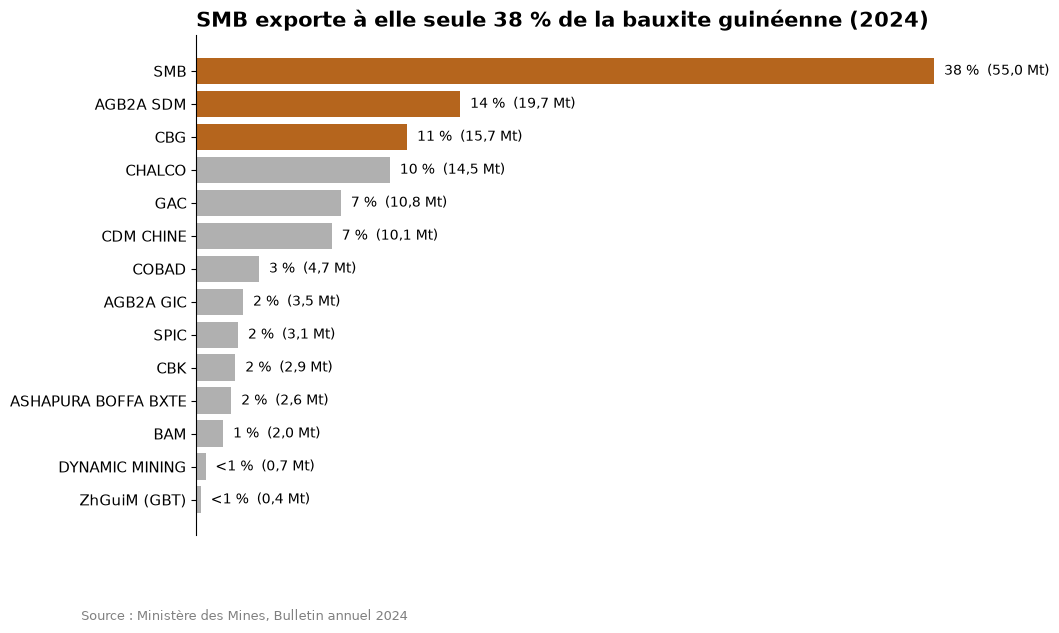

In [4]:
parts = requete("02_parts_entreprises", annee=2024).df()
print(parts.round(1))
graphique_parts_entreprises(parts, 2024)

**Conclusion :** en 2024, SMB exporte à elle seule 38 % de la bauxite guinéenne (55 Mt). Les trois premières entreprises (SMB, AGB2A SDM, CBG) font 62 % des exportations, et les six premières 86 %. Le secteur dépend donc de quelques acteurs : l'arrêt d'une seule grande mine pèserait lourd sur les exportations du pays.

## 2. Qui a porté le boom 2019-2024 ?

entreprise  AGB2A SDM   CBG  CDM CHINE  CHALCO   GAC   SMB
annee                                                     
2019              NaN  13.3        6.9     NaN   0.8  35.3
2020              0.4  16.2        5.9     5.6  10.3  32.7
2021              0.8  16.1        4.8    12.3  11.6  31.5
2022              2.1  16.2        9.9    14.7  14.5  35.9
2023              8.4  16.9        9.5    12.6  14.1  48.8
2024             19.7  15.7       10.1    14.5  10.8  55.0


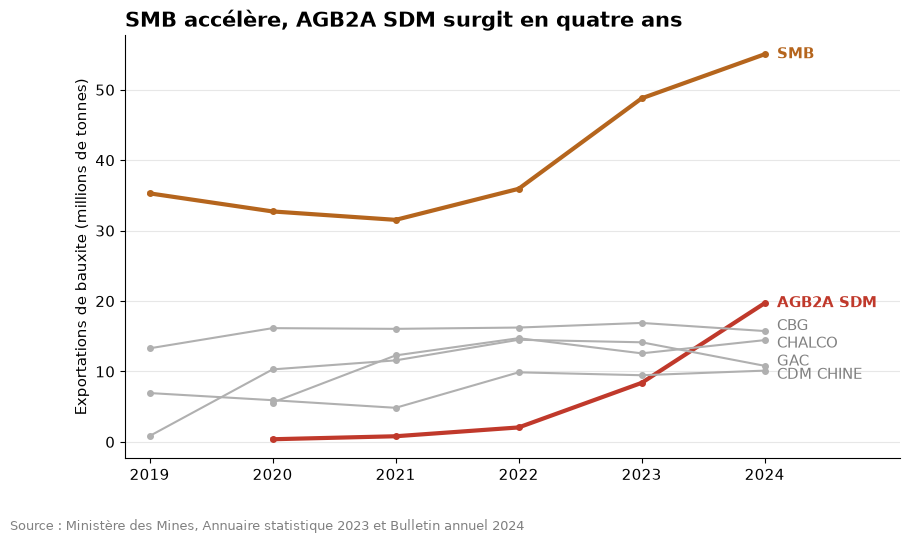

In [5]:
evolution = requete("02_evolution_top6", annee=2024).df()
tableau = evolution.pivot(index="annee", columns="entreprise", values="millions_tonnes")
print(tableau.round(1))
graphique_evolution_entreprises(tableau, a_souligner=["SMB", "AGB2A SDM"])

In [6]:
requete("02_contribution_hausse", debut=2019, fin=2024).show()

┌────────────┬───────────┬───────────────────────┐
│ entreprise │ hausse_mt │ part_de_la_hausse_pct │
│  varchar   │  double   │        double         │
├────────────┼───────────┼───────────────────────┤
│ SMB        │      19.8 │                  24.8 │
│ AGB2A SDM  │      19.7 │                  24.8 │
│ CHALCO     │      14.5 │                  18.2 │
│ GAC        │      10.0 │                  12.5 │
│ AGB2A GIC  │       3.5 │                   4.4 │
│ CDM CHINE  │       3.2 │                   4.0 │
└────────────┴───────────┴───────────────────────┘



**Conclusion :** entre 2019 et 2024, les exportations de bauxite ont augmenté de près de 80 Mt. SMB (+20 Mt) et AGB2A SDM (+19 Mt, partie de zéro en 2020) en expliquent environ la moitié. Viennent ensuite CHALCO et GAC, qui démarrent ou décollent en 2020. CBG, l'exploitant historique, reste stable autour de 16 Mt.

## 3. Que touche l'État par tonne exportée ?

            entreprise  taxe_miniere_usd  exportation_t  usd_par_tonne
0            AGB2A SDM      7.519334e+07       19703566           3.82
1  ASHAPURA BOFFA BXTE      5.242355e+06        2628626           1.99
2                  BAM      3.100146e+06        2022496           1.53
3            CDM CHINE      3.295944e+07       10124336           3.26
4               CHALCO      5.259811e+07       14454608           3.64
5                  GAC      2.476264e+07       10806153           2.29
6                  SMB      1.584135e+08       55049360           2.88


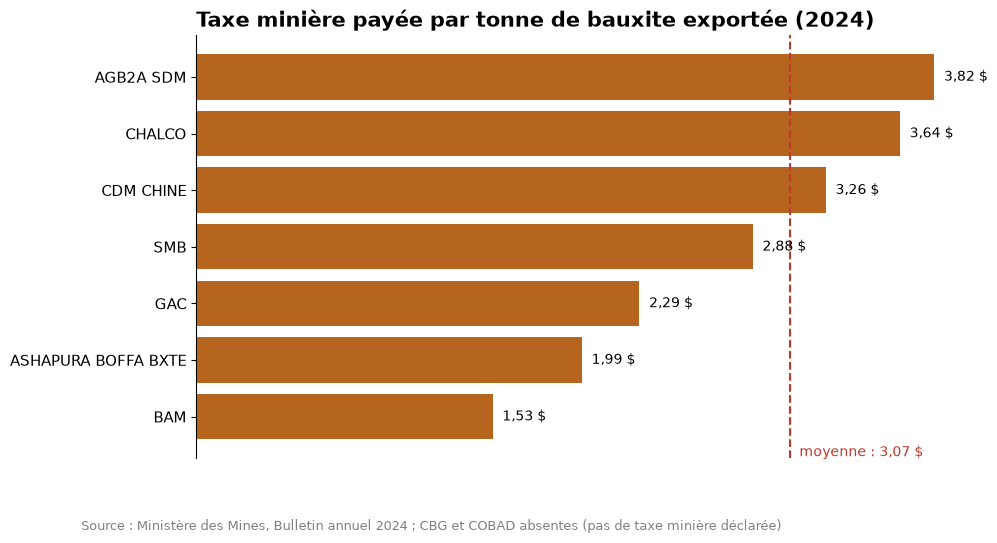

In [7]:
taxes = requete("02_taxe_par_tonne", annee=2024).df()
print(taxes.round(2))
graphique_taxe_par_tonne(taxes, 2024)

In [8]:
requete("02_part_pour_l_etat", annee=2024, taux_usd_gnf=TAUX_USD_GNF_2024).show()

┌───────────────────────────────┬────────────────────────────────────┬──────────────────────┐
│ recettes_bauxite_millions_usd │ exportations_bauxite_milliards_usd │ part_pour_l_etat_pct │
│            double             │               double               │        double        │
├───────────────────────────────┼────────────────────────────────────┼──────────────────────┤
│                         428.0 │                               4.71 │                  9.1 │
└───────────────────────────────┴────────────────────────────────────┴──────────────────────┘



**Conclusion :** en 2024, la taxe minière payée par tonne exportée va de 1,5 $ (BAM) à 3,8 $ (AGB2A SDM), avec une moyenne d'environ 3,1 $ pour les entreprises qui la paient. Au total, les sociétés bauxitiques ont versé environ 428 millions de dollars (taxe minière, douane, contribution communautaire), soit environ 9 % de la valeur des exportations de bauxite (4,7 milliards de dollars selon l'INS).

**Limites à signaler :**
- Ce calcul ne compte que les paiements publiés par le ministère. Il manque l'impôt sur les sociétés et les dividendes de l'État dans les sociétés où il est actionnaire, publiés dans les rapports ITIE.
- CBG ne paie pas de taxe minière : elle est régie par une convention spéciale, et l'État guinéen en est actionnaire.
- Les écarts de taxe par tonne entre entreprises peuvent venir de prix de vente, de qualités de bauxite ou de conventions différentes. Les données ne permettent pas de trancher.

## 4. L'or : quelques entreprises industrielles

In [9]:
requete("02_or_par_entreprise").show()

┌────────────┬─────────┬─────────┬─────────┬───────────────┐
│ entreprise │ kg_2019 │ kg_2023 │ kg_2024 │ part_2024_pct │
│  varchar   │ int128  │ int128  │ int128  │    double     │
├────────────┼─────────┼─────────┼─────────┼───────────────┤
│ SAG        │    7787 │    8627 │    8488 │          45.1 │
│ SMD        │    5876 │    4447 │    4667 │          24.8 │
│ SMM        │    NULL │    2307 │    3890 │          20.7 │
│ KGM        │    NULL │      37 │    1332 │           7.1 │
│ NJMC       │    NULL │     517 │     457 │           2.4 │
│ GBG        │    NULL │     409 │    NULL │          NULL │
│ R&R        │    NULL │       7 │    NULL │          NULL │
│ TRUSTACO   │    NULL │       2 │    NULL │          NULL │
│ GGE        │    NULL │    1154 │    NULL │          NULL │
└────────────┴─────────┴─────────┴─────────┴───────────────┘



**Conclusion :** la Société AngloGold Ashanti de Guinée (SAG) produit à elle seule près de la moitié de l'or industriel du pays (45 % en 2024), suivie de SMD et SMM. L'or industriel ne représente qu'une partie de l'or exporté : l'orpaillage artisanal en exporte davantage (environ 52 t en 2024 selon le même bulletin), ce qui rend l'or bien plus difficile à suivre et à taxer que la bauxite.

## Ce qu'il faut retenir

1. **Un secteur concentré :** SMB exporte 38 % de la bauxite guinéenne, et 3 entreprises en exportent 62 % (2024).
2. **Le boom vient surtout de deux acteurs :** SMB et AGB2A SDM expliquent environ la moitié des 80 Mt supplémentaires exportées entre 2019 et 2024.
3. **L'État touche environ 9 % de la valeur exportée** en taxes minières, droits de douane et contributions communautaires, soit environ 3 $ de taxe minière par tonne pour les entreprises qui la paient.
4. **La qualité des données compte :** le total 2022 publié par l'Annuaire était faux de 9 Mt ; la somme par entreprise et le Bulletin 2024 l'ont révélé.

**Prochaine étape :** à qui la Guinée vend sa bauxite (données miroir UN Comtrade), et la place de la Chine.